# Stage 5 — Reinforcement-Learning-Based Adaptive Routing

This notebook extends Stage 4 with a **contextual-bandit policy**. The Stage 2 gate continues to identify the requested task, and the Stage 4 quality head estimates whether that task's expert is likely to succeed. Stage 5 learns whether to **dispatch the selected expert** or **abstain and request review**.

A contextual bandit is a one-step reinforcement-learning formulation: each request is a context, the system selects an action, and an immediate outcome provides reward. This project has no multi-step episodes or delayed rewards, so a contextual bandit is a better fit than DQN or PPO.

### What this notebook adds
- Reuses the Stage 4 router and Stage 1 YOLO experts.
- Builds context features from routing probabilities, predicted expert success, and task identity.
- Defines `dispatch` and `abstain` actions with explicit rewards.
- Learns a policy by maximizing expected reward from feedback.
- Compares the policy against the Stage 4 quality-threshold rule.
- Evaluates reward, dispatch coverage, and observed success among dispatched requests.
- Saves a Stage 5 policy checkpoint and configuration.
- Demonstrates inference.

### Decision flow

```mermaid
flowchart TD
 A[Image + Text] --> B[Stage 2 Task Gate]
 B --> C{Clear task and confident?}
 C -->|No| X[Clarify / Abstain]
 C -->|Yes| D[Stage 4 Success Predictor]
 D --> E[Context Features]
 E --> F[Stage 5 Contextual-Bandit Policy]
 F --> G{Action}
 G -->|Dispatch| H[Selected YOLO Expert]
 G -->|Abstain| I[Review Required]
 H --> J[Task Output]
```

The policy does **not** choose classification versus segmentation. It decides whether to execute the task already selected by the semantic gate. This prevents the RL policy from violating the user's requested task.

### Learning objective

\[
J(\theta)=\frac{1}{N}\sum_i\sum_a \pi_\theta(a\mid s_i)R(s_i,a)
\]

Here, \(s_i\) is the request context, \(a\) is dispatch or abstain, and \(R\) is the configured immediate reward. The notebook uses an offline, full-feedback contextual-bandit objective; it does not perform live exploration against users.

## 1. Environment, platform and device

Install dependencies, detect CUDA / Apple MPS / CPU, and create portable project directories. Google Colab optionally mounts Drive.

In [1]:
%pip install -q open_clip_torch ultralytics opencv-python-headless torchvision matplotlib pillow pandas

import os, sys, json, random, platform, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/yolo_moe_project")
else:
    PROJECT_DIR = Path.cwd() / "yolo_moe_project"

DATA_DIR = PROJECT_DIR / "data"
ARTIFACT_DIR = PROJECT_DIR / "artifacts"
FEEDBACK_DIR = PROJECT_DIR / "feedback"
FEEDBACK_IMAGE_DIR = FEEDBACK_DIR / "images"
for folder in (DATA_DIR, ARTIFACT_DIR, FEEDBACK_DIR, FEEDBACK_IMAGE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
NUM_WORKERS = 0
PIN_MEMORY = DEVICE.type == "cuda"

def get_ultralytics_device(device):
    """Convert a PyTorch device into an Ultralytics-compatible device argument."""
    return 0 if device.type == "cuda" else ("mps" if device.type == "mps" else "cpu")

YOLO_DEVICE = get_ultralytics_device(DEVICE)
print("OS:", platform.platform(), "| Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__, "| Device:", DEVICE)
print("Project:", PROJECT_DIR)

Note: you may need to restart the kernel to use updated packages.
OS: macOS-26.5.2-arm64-arm-64bit-Mach-O | Python: 3.13.18
PyTorch: 2.15.0 | Device: mps
Project: /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project


## 2. Check Stage 4 and Stage 1 artifacts

Stage 5 starts from the Stage 4 feedback-adaptive router and reuses the two Stage 1 YOLO experts. It trains a separate policy; it does not retrain CLIP, the task gate, the quality head, or the YOLO experts.

In [2]:
STAGE4_ROUTER_PATH = ARTIFACT_DIR / "router_feedback_adaptive.pt"
STAGE4_CONFIG_PATH = ARTIFACT_DIR / "moe_feedback_adaptive_config.json"
CLS_WEIGHTS_PATH = ARTIFACT_DIR / "classification_best.pt"
SEG_WEIGHTS_PATH = ARTIFACT_DIR / "segmentation_best.pt"

required = [STAGE4_ROUTER_PATH, STAGE4_CONFIG_PATH, CLS_WEIGHTS_PATH, SEG_WEIGHTS_PATH]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Complete Stages 1–4 first. Missing artifacts:\n" + "\n".join(missing)
    )

try:
    stage4_checkpoint = torch.load(STAGE4_ROUTER_PATH, map_location="cpu", weights_only=False)
except TypeError:
    stage4_checkpoint = torch.load(STAGE4_ROUTER_PATH, map_location="cpu")
stage4_config = json.loads(STAGE4_CONFIG_PATH.read_text(encoding="utf-8"))

ROUTING_TEMPERATURE = float(stage4_checkpoint.get("temperature", 1.0))
ROUTING_THRESHOLD = float(stage4_checkpoint.get("routing_threshold", 0.70))
QUALITY_THRESHOLD = float(stage4_checkpoint.get("quality_threshold", 0.60))
SEGMENTATION_SUCCESS_IOU = float(stage4_checkpoint.get("segmentation_success_iou", 0.50))
print("All required checkpoints and configuration files found.")

All required checkpoints and configuration files found.


## 3. Configure feedback, rewards, and policy training

The rewards below are illustrative. Change them to represent the application's costs. A failed dispatch is penalized more heavily than abstention; successful dispatch is rewarded.

In [3]:
USE_GROUND_TRUTH_BOOTSTRAP = True
MAX_BOOTSTRAP_IMAGES = 400
EXPERT_INFERENCE_BATCH = 16

FEEDBACK_CSV = FEEDBACK_DIR / "feedback_log.csv"
BOOTSTRAP_CSV = FEEDBACK_DIR / "rl_bootstrap_feedback.csv"
FEEDBACK_TEMPLATE_CSV = FEEDBACK_DIR / "feedback_log_template.csv"
FEEDBACK_COLUMNS = ["image_path", "prompt", "task_id", "success", "source_id"]

REWARD_SUCCESSFUL_DISPATCH = 1.0
REWARD_FAILED_DISPATCH = -1.0
REWARD_ABSTAIN = -0.10

POLICY_HIDDEN_DIM = 64
POLICY_EPOCHS = 40
POLICY_LEARNING_RATE = 1e-3
POLICY_WEIGHT_DECAY = 1e-4
ENTROPY_COEFFICIENT = 0.01
BATCH_SIZE = 64

if not FEEDBACK_TEMPLATE_CSV.exists():
    pd.DataFrame(columns=FEEDBACK_COLUMNS).to_csv(FEEDBACK_TEMPLATE_CSV, index=False)

print("Feedback file:", FEEDBACK_CSV)
print("Reward values:", REWARD_SUCCESSFUL_DISPATCH, REWARD_FAILED_DISPATCH, REWARD_ABSTAIN)

Feedback file: /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project/feedback/feedback_log.csv
Reward values: 1.0 -1.0 -0.1


## 4. Reconstruct the Stage 4 router

This class matches the Stage 3 / Stage 4 architecture. The Stage 4 checkpoint restores both the three-way task gate and the two-output expert-success head. All router parameters are frozen in Stage 5.

In [4]:
import open_clip

class CLIPPerformanceAwareRouter(nn.Module):
    """Stage 2 CLIP router augmented with task-specific expert-success logits.

    Inputs:
        images: RGB float tensor [B,3,224,224] in [0,1].
        prompts: list[str] containing B task instructions.
    Output:
        Dict with routing_logits [B,3] and quality_logits [B,2].
        Quality output 0 is classification success; output 1 is segmentation success.
    """
    def __init__(self, clip_model_name="ViT-B-32",
                 clip_pretrained="laion2b_s34b_b79k", hidden_dim=256, dropout=0.1):
        super().__init__()
        self.clip_model_name = clip_model_name
        self.clip_pretrained = clip_pretrained
        self.clip_model, _, _ = open_clip.create_model_and_transforms(
            model_name=clip_model_name, pretrained=clip_pretrained
        )
        self.tokenizer = open_clip.get_tokenizer(clip_model_name)
        self.register_buffer("clip_mean", torch.tensor(
            [0.48145466, 0.4578275, 0.40821073]).view(1,3,1,1))
        self.register_buffer("clip_std", torch.tensor(
            [0.26862954, 0.26130258, 0.27577711]).view(1,3,1,1))
        for p in self.clip_model.parameters():
            p.requires_grad = False
        self.clip_model.eval()
        with torch.no_grad():
            dummy = torch.zeros(1,3,224,224)
            feature_dim = self.clip_model.encode_image(
                (dummy - self.clip_mean) / self.clip_std
            ).shape[-1]
        fused_dim = feature_dim * 3
        self.gate = nn.Sequential(
            nn.Linear(fused_dim, hidden_dim), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(hidden_dim, 3))
        self.quality_head = nn.Sequential(
            nn.Linear(fused_dim, hidden_dim), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(hidden_dim, 2))

    def train(self, mode=True):
        """Set module mode while keeping frozen CLIP in evaluation mode."""
        super().train(mode)
        self.clip_model.eval()
        return self

    def forward(self, images, prompts):
        """Return task-routing logits and task-specific expert-success logits."""
        images = (images - self.clip_mean.to(images.device)) / self.clip_std.to(images.device)
        tokens = self.tokenizer(prompts).to(images.device)
        with torch.no_grad():
            image_features = self.clip_model.encode_image(images)
            text_features = self.clip_model.encode_text(tokens)
        image_features = F.normalize(image_features.float(), dim=-1)
        text_features = F.normalize(text_features.float(), dim=-1)
        fused = torch.cat(
            [image_features, text_features, image_features * text_features], dim=-1
        )
        return {"routing_logits": self.gate(fused),
                "quality_logits": self.quality_head(fused)}

router = CLIPPerformanceAwareRouter(
    clip_model_name=stage4_checkpoint["clip_model_name"],
    clip_pretrained=stage4_checkpoint["clip_pretrained"],
    hidden_dim=int(stage4_checkpoint.get("hidden_dim", 256)),
    dropout=float(stage4_checkpoint.get("dropout", 0.1))
).to(DEVICE)
router.load_state_dict(stage4_checkpoint["model_state_dict"], strict=True)
router.eval()
for parameter in router.parameters():
    parameter.requires_grad = False
print("Stage 4 router loaded and frozen.")

/Users/christy.manthara/repositories/MoE-cls-seg/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Stage 4 router loaded and frozen.


## 5. Define task-specific outcome measurements

Bootstrap feedback uses the same success criteria as Stages 3 and 4: top-1 classification correctness and segmentation foreground IoU.

In [5]:
DECISION_CLASSIFICATION = 0
DECISION_SEGMENTATION = 1
DECISION_CLARIFY = 2
DECISION_NAMES = {0: "classification", 1: "segmentation", 2: "clarify"}

from ultralytics import YOLO
cls_expert = YOLO(str(CLS_WEIGHTS_PATH))
seg_expert = YOLO(str(SEG_WEIGHTS_PATH))

def segmentation_iou_from_result(result, ground_truth_mask):
    """Compute foreground IoU between one YOLO result and a binary target mask."""
    gt = (ground_truth_mask > 0).astype(np.uint8)
    if result.masks is None or result.masks.data is None or len(result.masks.data) == 0:
        pred = np.zeros_like(gt, dtype=np.uint8)
    else:
        masks = result.masks.data.detach().float().cpu().numpy()
        combined = masks.max(axis=0) > 0.5
        pred = cv2.resize(combined.astype(np.uint8), (gt.shape[1], gt.shape[0]),
                          interpolation=cv2.INTER_NEAREST)
    intersection = np.logical_and(pred > 0, gt > 0).sum()
    union = np.logical_or(pred > 0, gt > 0).sum()
    return float(intersection / union) if union else 1.0

print("Classification success: top-1 correct.")
print("Segmentation success: foreground IoU >=", SEGMENTATION_SUCCESS_IOU)

Classification success: top-1 correct.
Segmentation success: foreground IoU >= 0.5


## 6. Generate optional ground-truth bootstrap feedback

If enabled, both experts are evaluated on a reproducible subset of Oxford-IIIT Pet test images. This generates observed outcomes for the feedback table. It is annotation-derived proxy feedback, not human review or live user interaction.

In [6]:
bootstrap_rows = []
if USE_GROUND_TRUTH_BOOTSTRAP:
    feedback_dataset = datasets.OxfordIIITPet(
        root=str(DATA_DIR), split="test",
        target_types=["category", "segmentation"], download=True
    )
    indices = list(range(len(feedback_dataset)))
    random.Random(SEED + 505).shuffle(indices)
    indices = indices[:min(MAX_BOOTSTRAP_IMAGES, len(indices))]

    images, metadata = [], []
    for idx in indices:
        image, (category_id, trimap) = feedback_dataset[idx]
        image = image.convert("RGB")
        trimap_array = np.asarray(trimap, dtype=np.uint8)
        images.append(image)
        metadata.append({
            "idx": int(idx), "image": image,
            "class_label": int(category_id) - 1,
            "gt_mask": (trimap_array == 1) | (trimap_array == 3)
        })

    cls_results = cls_expert.predict(
        source=images, batch=EXPERT_INFERENCE_BATCH, imgsz=224,
        device=YOLO_DEVICE, verbose=False)
    seg_results = seg_expert.predict(
        source=images, batch=EXPERT_INFERENCE_BATCH, imgsz=640,
        device=YOLO_DEVICE, verbose=False)

    for meta, cls_result, seg_result in zip(metadata, cls_results, seg_results):
        if cls_result.probs is None:
            raise RuntimeError("Classification expert returned no class probabilities.")
        cls_success = int(int(cls_result.probs.top1) == meta["class_label"])
        seg_iou = segmentation_iou_from_result(seg_result, meta["gt_mask"])
        seg_success = int(seg_iou >= SEGMENTATION_SUCCESS_IOU)

        image_path = FEEDBACK_IMAGE_DIR / f"rl_oxford_test_{meta['idx']:05d}.jpg"
        meta["image"].save(image_path, quality=95)
        source_id = f"rl_oxford_test_{meta['idx']}"
        bootstrap_rows.extend([
            {"image_path": str(image_path),
             "prompt": "Classify the pet breed in this image.",
             "task_id": 0, "success": cls_success, "source_id": source_id},
            {"image_path": str(image_path),
             "prompt": "Segment the pet from the background.",
             "task_id": 1, "success": seg_success, "source_id": source_id}
        ])

    pd.DataFrame(bootstrap_rows, columns=FEEDBACK_COLUMNS).to_csv(BOOTSTRAP_CSV, index=False)
    print("Bootstrap feedback rows:", len(bootstrap_rows))
else:
    print("Bootstrap disabled; using reviewed feedback if available.")

WARNING ⚠️ NMS time limit 2.050s exceeded
Bootstrap feedback rows: 800


## 7. Load and validate feedback

The feedback schema is compatible with Stage 4. `source_id` is used to split by original image and avoid source-image overlap between training and evaluation data.

In [7]:
frames = []
if BOOTSTRAP_CSV.exists():
    frames.append(pd.read_csv(BOOTSTRAP_CSV)[FEEDBACK_COLUMNS])
if FEEDBACK_CSV.exists():
    manual_df = pd.read_csv(FEEDBACK_CSV)
    missing_columns = [c for c in FEEDBACK_COLUMNS if c not in manual_df.columns]
    if missing_columns:
        raise ValueError(f"feedback_log.csv missing columns: {missing_columns}")
    frames.append(manual_df[FEEDBACK_COLUMNS].copy())
    print("Reviewed feedback rows:", len(manual_df))
else:
    print("No reviewed feedback file found.")

if not frames:
    raise ValueError("No feedback found. Enable bootstrap or create feedback_log.csv.")

feedback_df = pd.concat(frames, ignore_index=True)
feedback_df["task_id"] = pd.to_numeric(feedback_df["task_id"], errors="raise").astype(int)
feedback_df["success"] = pd.to_numeric(feedback_df["success"], errors="raise").astype(int)
for column in ["image_path", "prompt", "source_id"]:
    feedback_df[column] = feedback_df[column].astype(str)

if not feedback_df["task_id"].isin([0,1]).all():
    raise ValueError("task_id must be 0 or 1.")
if not feedback_df["success"].isin([0,1]).all():
    raise ValueError("success must be 0 or 1.")
missing_images = [p for p in feedback_df.image_path.unique() if not Path(p).exists()]
if missing_images:
    raise FileNotFoundError(f"Missing feedback images, e.g. {missing_images[:3]}")

feedback_df = feedback_df.drop_duplicates().reset_index(drop=True)
print("Feedback rows:", len(feedback_df))
print("Unique source images:", feedback_df.source_id.nunique())
display(feedback_df.head())

No reviewed feedback file found.
Feedback rows: 800
Unique source images: 400


,image_path,prompt,task_id,success,source_id
0,/Users/christy.manthara/repositories/MoE-cls-s...,Classify the pet breed in this image.,0,1,rl_oxford_test_1591
1,/Users/christy.manthara/repositories/MoE-cls-s...,Segment the pet from the background.,1,1,rl_oxford_test_1591
2,/Users/christy.manthara/repositories/MoE-cls-s...,Classify the pet breed in this image.,0,1,rl_oxford_test_3636
3,/Users/christy.manthara/repositories/MoE-cls-s...,Segment the pet from the background.,1,1,rl_oxford_test_3636
4,/Users/christy.manthara/repositories/MoE-cls-s...,Classify the pet breed in this image.,0,1,rl_oxford_test_2947


## 8. Split feedback by source image

All task rows associated with the same source image stay in the same split.

In [8]:
unique_sources = feedback_df.source_id.unique().tolist()
if len(unique_sources) < 4:
    raise ValueError("At least four unique source_id values are recommended.")

random.Random(SEED + 506).shuffle(unique_sources)
split_at = max(1, int(0.8 * len(unique_sources)))
train_sources = set(unique_sources[:split_at])
eval_sources = set(unique_sources[split_at:])

train_df = feedback_df[feedback_df.source_id.isin(train_sources)].reset_index(drop=True)
eval_df = feedback_df[feedback_df.source_id.isin(eval_sources)].reset_index(drop=True)
if train_df.empty or eval_df.empty:
    raise ValueError("Feedback split produced an empty subset.")
assert not (set(train_df.source_id) & set(eval_df.source_id))
print("Train rows:", len(train_df), "| Evaluation rows:", len(eval_df))

Train rows: 640 | Evaluation rows: 160


## 9. Create feedback datasets and data loaders

In [9]:
class FeedbackDataset(Dataset):
    """Load an image, prompt, task ID, observed success, and source ID from feedback.

    Args:
        frame: DataFrame containing the feedback schema.
        image_size: Image side length required by the CLIP router.

    Returns:
        Dict with image tensor [3,image_size,image_size], prompt, task_id,
        success label, and source_id.
    """
    def __init__(self, frame, image_size=224):
        self.frame = frame.reset_index(drop=True).copy()
        self.image_size = image_size

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        image = Image.open(row.image_path).convert("RGB")
        image = image.resize((self.image_size, self.image_size), Image.Resampling.BICUBIC)
        array = np.asarray(image, dtype=np.float32) / 255.0
        return {
            "image": torch.from_numpy(array).permute(2,0,1).contiguous(),
            "prompt": str(row.prompt),
            "task_id": torch.tensor(int(row.task_id), dtype=torch.long),
            "success": torch.tensor(float(row.success), dtype=torch.float32),
            "source_id": str(row.source_id)
        }

def collate_feedback_batch(batch):
    """Stack image/label tensors and preserve text and source IDs as Python lists."""
    return {
        "images": torch.stack([x["image"] for x in batch]),
        "prompts": [x["prompt"] for x in batch],
        "task_ids": torch.stack([x["task_id"] for x in batch]),
        "success": torch.stack([x["success"] for x in batch]),
        "source_ids": [x["source_id"] for x in batch]
    }

train_loader = DataLoader(
    FeedbackDataset(train_df), batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
    collate_fn=collate_feedback_batch)
eval_loader = DataLoader(
    FeedbackDataset(eval_df), batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
    collate_fn=collate_feedback_batch)
print("Train batches:", len(train_loader), "| Eval batches:", len(eval_loader))

Train batches: 10 | Eval batches: 3


## 10. Extract contextual features from the frozen Stage 4 model

Each context has seven features: three routing probabilities, the requested expert's predicted success probability, a two-value task one-hot vector, and maximum routing confidence.

Only rows where the Stage 2 gate agrees with the task label and exceeds its routing threshold are eligible for policy learning. Ambiguous, low-confidence, or task-mismatched requests remain handled by the fixed Stage 2 guard.

In [10]:
CONTEXT_DIM = 7

@torch.no_grad()
def collect_bandit_contexts(model, loader, device=DEVICE):
    """Extract eligible request contexts and retain their observed expert outcomes.

    Eligibility requires the Stage 2 top routing decision to match the feedback
    task_id and routing confidence to meet ROUTING_THRESHOLD.

    Returns:
        Dict with contexts [N,7], task_ids [N], success [N],
        routing_confidence [N], and quality_probability [N].
    """
    model.eval()
    contexts, tasks_out, success_out = [], [], []
    confidence_out, quality_out = [], []

    for batch in loader:
        images = batch["images"].to(device)
        tasks = batch["task_ids"].to(device)
        successes = batch["success"].to(device)
        output = model(images, batch["prompts"])

        routing_probs = torch.softmax(
            output["routing_logits"] / ROUTING_TEMPERATURE, dim=-1)
        selected_route = routing_probs.argmax(dim=-1)
        routing_confidence = routing_probs.max(dim=-1).values
        selected_quality = torch.sigmoid(
            output["quality_logits"].gather(1, tasks[:,None]).squeeze(1))
        task_one_hot = F.one_hot(tasks, num_classes=2).float()

        context = torch.cat([
            routing_probs,
            selected_quality[:,None],
            task_one_hot,
            routing_confidence[:,None]
        ], dim=1)

        eligible = (selected_route == tasks) & (routing_confidence >= ROUTING_THRESHOLD)
        if eligible.any():
            contexts.append(context[eligible].cpu())
            tasks_out.append(tasks[eligible].cpu())
            success_out.append(successes[eligible].cpu())
            confidence_out.append(routing_confidence[eligible].cpu())
            quality_out.append(selected_quality[eligible].cpu())

    if not contexts:
        raise ValueError(
            "No eligible examples. Check task prompts, task_id values, and routing threshold."
        )
    return {
        "contexts": torch.cat(contexts),
        "task_ids": torch.cat(tasks_out),
        "success": torch.cat(success_out),
        "routing_confidence": torch.cat(confidence_out),
        "quality_probability": torch.cat(quality_out)
    }

train_features = collect_bandit_contexts(router, train_loader)
eval_features = collect_bandit_contexts(router, eval_loader)
print("Eligible train contexts:", len(train_features["success"]))
print("Eligible eval contexts:", len(eval_features["success"]))
print("Context dimension:", train_features["contexts"].shape[1])

Eligible train contexts: 640
Eligible eval contexts: 160
Context dimension: 7


## 11. Define actions and rewards

Action `0` dispatches the selected task expert. Action `1` abstains and requests review. The feedback row supplies the observed reward for dispatch; abstention receives a fixed configured reward.

This is **offline full-feedback contextual-bandit learning**. The notebook does not fabricate the outcome of an unselected expert.

In [11]:
ACTION_DISPATCH = 0
ACTION_ABSTAIN = 1
ACTION_NAMES = {0: "dispatch", 1: "abstain"}

def make_reward_matrix(success_labels):
    """Build a [N,2] reward table for dispatch and abstention.

    Args:
        success_labels: Tensor [N] containing binary observed expert outcomes.
    Returns:
        Float tensor [N,2] with dispatch reward in column 0 and abstain reward
        in column 1.
    """
    labels = success_labels.float()
    dispatch = torch.where(
        labels >= 0.5,
        torch.full_like(labels, REWARD_SUCCESSFUL_DISPATCH),
        torch.full_like(labels, REWARD_FAILED_DISPATCH)
    )
    abstain = torch.full_like(labels, REWARD_ABSTAIN)
    return torch.stack([dispatch, abstain], dim=1)

train_rewards = make_reward_matrix(train_features["success"])
eval_rewards = make_reward_matrix(eval_features["success"])
print("Reward table sample [dispatch, abstain]:")
print(train_rewards[:5])

Reward table sample [dispatch, abstain]:
tensor([[ 1.0000, -0.1000],
        [ 1.0000, -0.1000],
        [ 1.0000, -0.1000],
        [ 1.0000, -0.1000],
        [ 1.0000, -0.1000]])


## 12. Define the contextual-bandit policy

A small MLP maps each seven-dimensional context to two action logits. Softmax converts logits into probabilities for dispatch and abstain.

In [12]:
class ContextualBanditPolicy(nn.Module):
    """Map a request context to dispatch/abstain action logits.

    Args:
        context_dim: number of context features.
        hidden_dim: width of the policy's hidden layers.

    Input:
        contexts: float tensor [B, context_dim].
    Output:
        Logits tensor [B, 2], ordered as dispatch then abstain.
    """
    def __init__(self, context_dim=CONTEXT_DIM, hidden_dim=64):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(context_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, contexts):
        """Return unnormalized action scores."""
        return self.network(contexts)

policy = ContextualBanditPolicy(CONTEXT_DIM, POLICY_HIDDEN_DIM).to(DEVICE)
print("Trainable policy parameters:",
      sum(p.numel() for p in policy.parameters()))

Trainable policy parameters: 4802


## 13. Train by maximizing expected reward

For every feedback context, the reward for dispatch and abstain is available. The objective therefore computes the expected reward directly:

\[
J(\theta)=\frac{1}{N}\sum_i\sum_a \pi_\theta(a\mid s_i)R(s_i,a)
\]

The optimization minimizes negative expected reward and adds a small entropy bonus. This is a policy-gradient objective for a contextual bandit with a known per-example reward table.

In [13]:
optimizer = torch.optim.AdamW(
    policy.parameters(), lr=POLICY_LEARNING_RATE,
    weight_decay=POLICY_WEIGHT_DECAY)

train_contexts = train_features["contexts"].to(DEVICE)
train_reward_matrix = train_rewards.to(DEVICE)
eval_contexts = eval_features["contexts"].to(DEVICE)
eval_reward_matrix = eval_rewards.to(DEVICE)

history = []
for epoch in range(1, POLICY_EPOCHS + 1):
    policy.train()
    optimizer.zero_grad(set_to_none=True)
    probs = torch.softmax(policy(train_contexts), dim=-1)
    expected_reward = (probs * train_reward_matrix).sum(dim=1).mean()
    entropy = -(probs * torch.log(probs.clamp_min(1e-8))).sum(dim=1).mean()
    loss = -expected_reward - ENTROPY_COEFFICIENT * entropy
    loss.backward()
    optimizer.step()

    policy.eval()
    with torch.no_grad():
        eval_probs = torch.softmax(policy(eval_contexts), dim=-1)
        eval_expected_reward = (eval_probs * eval_reward_matrix).sum(dim=1).mean()

    history.append({
        "epoch": epoch,
        "train_expected_reward": float(expected_reward.item()),
        "eval_expected_reward": float(eval_expected_reward.item()),
        "entropy": float(entropy.item()),
        "loss": float(loss.item())
    })
    if epoch == 1 or epoch % 5 == 0:
        print(f"Epoch {epoch:02d} | train reward {expected_reward.item():.4f} "
              f"| eval reward {eval_expected_reward.item():.4f} "
              f"| entropy {entropy.item():.4f}")

history_df = pd.DataFrame(history)
display(history_df.tail())

Epoch 01 | train reward 0.3270 | eval reward 0.3275 | entropy 0.6921
Epoch 05 | train reward 0.3612 | eval reward 0.3597 | entropy 0.6926
Epoch 10 | train reward 0.3999 | eval reward 0.3980 | entropy 0.6862
Epoch 15 | train reward 0.4406 | eval reward 0.4391 | entropy 0.6714
Epoch 20 | train reward 0.4874 | eval reward 0.4867 | entropy 0.6438
Epoch 25 | train reward 0.5414 | eval reward 0.5409 | entropy 0.5969
Epoch 30 | train reward 0.5997 | eval reward 0.5982 | entropy 0.5261
Epoch 35 | train reward 0.6560 | eval reward 0.6520 | entropy 0.4337
Epoch 40 | train reward 0.7036 | eval reward 0.6960 | entropy 0.3314


,epoch,train_expected_reward,eval_expected_reward,entropy,loss
35,36,0.666430,0.661765,0.413428,-0.670564
36,37,0.676455,0.671078,0.392919,-0.680384
37,38,0.686028,0.679894,0.372286,-0.689751
38,39,0.695101,0.688183,0.351715,-0.698618
39,40,0.703640,0.695951,0.331370,-0.706954


## 14. Plot policy optimization

The curves show expected reward on the training and held-out evaluation contexts.

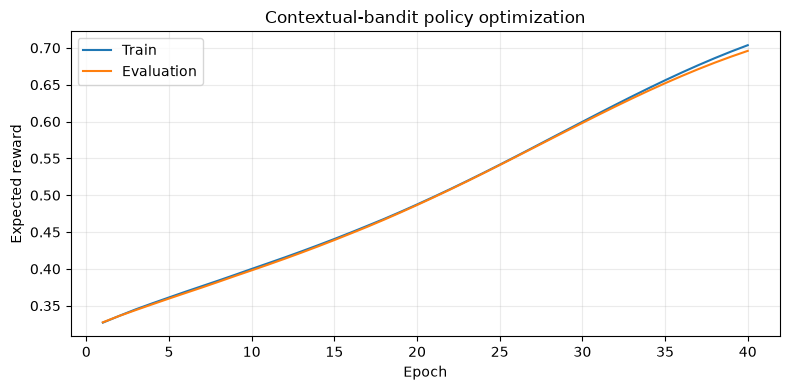

In [14]:
plt.figure(figsize=(8,4))
plt.plot(history_df.epoch, history_df.train_expected_reward, label="Train")
plt.plot(history_df.epoch, history_df.eval_expected_reward, label="Evaluation")
plt.xlabel("Epoch")
plt.ylabel("Expected reward")
plt.title("Contextual-bandit policy optimization")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## 15. Compare Stage 5 with the Stage 4 threshold policy

The Stage 4 baseline dispatches when its predicted expert-success probability is at least `QUALITY_THRESHOLD`; otherwise it abstains. Stage 5 uses the learned policy's most probable action.

Evaluation reports realized reward, expected reward, dispatch coverage, and observed success among dispatched examples.

In [15]:
def evaluate_action_policy(action_ids, action_probs, rewards, success_labels):
    """Compute reward and selective-coverage metrics for a chosen policy.

    Args:
        action_ids: Long tensor [N] of selected action IDs.
        action_probs: Float tensor [N,2] of action probabilities.
        rewards: Float tensor [N,2] of per-action rewards.
        success_labels: Float tensor [N] of observed expert success.
    Returns:
        Dictionary with average realized/expected reward, dispatch coverage,
        and success rate among dispatched examples.
    """
    chosen_reward = rewards.gather(1, action_ids[:,None]).squeeze(1)
    dispatched = action_ids == ACTION_DISPATCH
    coverage = float(dispatched.float().mean())
    success_rate = float(success_labels[dispatched].mean()) if dispatched.any() else float("nan")
    return {
        "average_realized_reward": float(chosen_reward.mean()),
        "average_expected_reward": float((action_probs * rewards).sum(dim=1).mean()),
        "dispatch_coverage": coverage,
        "success_among_dispatched": success_rate,
        "dispatch_count": int(dispatched.sum()),
        "total_count": int(action_ids.numel())
    }

policy.eval()
with torch.no_grad():
    stage5_probs = torch.softmax(policy(eval_contexts), dim=-1).cpu()
    stage5_actions = stage5_probs.argmax(dim=-1)

quality_eval = eval_features["quality_probability"]
stage4_actions = torch.where(
    quality_eval >= QUALITY_THRESHOLD,
    torch.full_like(quality_eval, ACTION_DISPATCH, dtype=torch.long),
    torch.full_like(quality_eval, ACTION_ABSTAIN, dtype=torch.long)
)
stage4_probs = F.one_hot(stage4_actions, num_classes=2).float()

stage4_metrics = evaluate_action_policy(
    stage4_actions, stage4_probs, eval_rewards, eval_features["success"])
stage5_metrics = evaluate_action_policy(
    stage5_actions, stage5_probs, eval_rewards, eval_features["success"])

comparison = pd.DataFrame(
    [stage4_metrics, stage5_metrics],
    index=["Stage 4 threshold policy", "Stage 5 contextual bandit"])
display(comparison)

,average_realized_reward,average_expected_reward,dispatch_coverage,success_among_dispatched,dispatch_count,total_count
Stage 4 threshold policy,0.785,0.785000,0.975,0.903846,156,160
Stage 5 contextual bandit,0.775,0.695951,1.000,0.887500,160,160


## 16. Inspect task-specific policy behavior

A useful policy should not be judged by reward alone. Inspect action distribution, task-specific coverage, and success among dispatched requests.

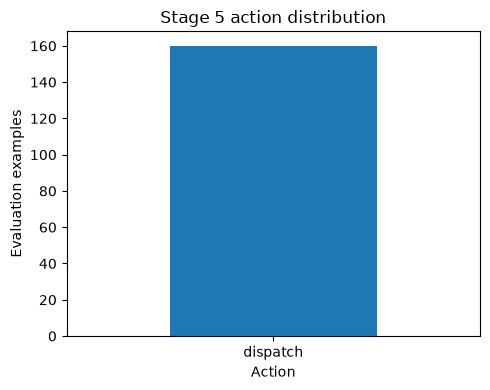

,average_realized_reward,average_expected_reward,dispatch_coverage,success_among_dispatched,dispatch_count,total_count,task
0,0.625,0.548632,1.0,0.8125,80,80,classification
1,0.925,0.843271,1.0,0.9625,80,80,segmentation


In [16]:
action_counts = pd.Series(
    [ACTION_NAMES[int(a)] for a in stage5_actions.tolist()]
).value_counts()
plt.figure(figsize=(5,4))
action_counts.plot(kind="bar")
plt.title("Stage 5 action distribution")
plt.xlabel("Action")
plt.ylabel("Evaluation examples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

task_rows = []
for task_id, task_name in [(0, "classification"), (1, "segmentation")]:
    mask = eval_features["task_ids"] == task_id
    if mask.any():
        metrics = evaluate_action_policy(
            stage5_actions[mask], stage5_probs[mask], eval_rewards[mask],
            eval_features["success"][mask])
        metrics["task"] = task_name
        task_rows.append(metrics)
display(pd.DataFrame(task_rows))

## 17. Inspect individual decisions

In [17]:
inspection_df = pd.DataFrame({
    "task": [DECISION_NAMES[int(x)] for x in eval_features["task_ids"].tolist()],
    "routing_confidence": eval_features["routing_confidence"].tolist(),
    "predicted_expert_success": eval_features["quality_probability"].tolist(),
    "p_dispatch": stage5_probs[:,0].tolist(),
    "p_abstain": stage5_probs[:,1].tolist(),
    "chosen_action": [ACTION_NAMES[int(x)] for x in stage5_actions.tolist()],
    "observed_success": eval_features["success"].tolist()
})
display(inspection_df.head(20))

,task,routing_confidence,predicted_expert_success,p_dispatch,p_abstain,chosen_action,observed_success
0,classification,1.0,0.924620,0.895224,0.104776,dispatch,1.0
1,segmentation,1.0,0.968609,0.920662,0.079338,dispatch,1.0
2,classification,1.0,0.765356,0.887987,0.112014,dispatch,0.0
3,segmentation,1.0,0.911650,0.919359,0.080641,dispatch,1.0
4,classification,1.0,0.950978,0.896385,0.103615,dispatch,1.0
5,segmentation,1.0,0.963635,0.920549,0.079451,dispatch,1.0
6,classification,1.0,0.877299,0.893111,0.106889,dispatch,1.0
7,segmentation,1.0,0.966477,0.920614,0.079386,dispatch,1.0
8,classification,1.0,0.811262,0.890111,0.109889,dispatch,1.0
9,segmentation,1.0,0.956472,0.920385,0.079615,dispatch,1.0


## 18. Save the Stage 5 policy and configuration

The policy checkpoint is separate from the Stage 4 router and Stage 1 experts. Keep all referenced artifacts together for inference.

In [18]:
STAGE5_POLICY_PATH = ARTIFACT_DIR / "router_rl_policy.pt"
STAGE5_CONFIG_PATH = ARTIFACT_DIR / "moe_rl_config.json"

stage5_checkpoint = {
    "policy_state_dict": policy.state_dict(),
    "context_dim": CONTEXT_DIM,
    "hidden_dim": POLICY_HIDDEN_DIM,
    "stage": 5,
    "algorithm": "offline_full_feedback_contextual_bandit",
    "reward_successful_dispatch": REWARD_SUCCESSFUL_DISPATCH,
    "reward_failed_dispatch": REWARD_FAILED_DISPATCH,
    "reward_abstain": REWARD_ABSTAIN,
    "entropy_coefficient": ENTROPY_COEFFICIENT
}
torch.save(stage5_checkpoint, STAGE5_POLICY_PATH)

stage5_config = {
    "architecture": "stage5_contextual_bandit_adaptive_moe",
    "stage": 5,
    "algorithm": "offline_full_feedback_contextual_bandit",
    "policy_checkpoint": STAGE5_POLICY_PATH.name,
    "stage4_router_checkpoint": STAGE4_ROUTER_PATH.name,
    "experts": {
        "classification": CLS_WEIGHTS_PATH.name,
        "segmentation": SEG_WEIGHTS_PATH.name
    },
    "context_features": [
        "three routing probabilities",
        "selected-task expert-success probability",
        "two-element task one-hot",
        "maximum routing probability"
    ],
    "actions": {"0": "dispatch selected task expert", "1": "abstain"},
    "rewards": {
        "successful_dispatch": REWARD_SUCCESSFUL_DISPATCH,
        "failed_dispatch": REWARD_FAILED_DISPATCH,
        "abstain": REWARD_ABSTAIN
    },
    "routing_temperature": ROUTING_TEMPERATURE,
    "routing_threshold": ROUTING_THRESHOLD,
    "stage4_quality_threshold": QUALITY_THRESHOLD,
    "updated_component": "contextual_bandit_policy_only",
    "frozen_components": [
        "CLIP encoder", "Stage 2 task gate", "Stage 4 quality head",
        "YOLO classification expert", "YOLO segmentation expert"
    ]
}
STAGE5_CONFIG_PATH.write_text(json.dumps(stage5_config, indent=2), encoding="utf-8")
print("Saved:", STAGE5_POLICY_PATH)
print("Saved:", STAGE5_CONFIG_PATH)

Saved: /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project/artifacts/router_rl_policy.pt
Saved: /Users/christy.manthara/repositories/MoE-cls-seg/yolo_moe_project/artifacts/moe_rl_config.json


## 19. Stage 5 inference wrapper

The Stage 2 routing guard is applied first. Ambiguous, low-confidence, or task-mismatched requests are abstained before the RL policy is consulted. For a clear task, the Stage 5 policy decides dispatch versus abstain.

In [19]:
class ReinforcementLearningMoE:
    """Inference wrapper combining Stage 4 context with a Stage 5 bandit policy.

    Args:
        router: loaded Stage 4 CLIPPerformanceAwareRouter.
        policy: trained ContextualBanditPolicy.
        cls_weights_path / seg_weights_path: Stage 1 YOLO checkpoints.
        routing_temperature: Stage 2 probability temperature.
        routing_threshold: minimum task-routing confidence.
        device: PyTorch device.

    predict() accepts an image path, PIL image, or [3,H,W] float tensor and a prompt.
    It returns routing probabilities, predicted expert success, bandit action
    probabilities, status, and a YOLO result if dispatch occurs.
    """
    def __init__(self, router, policy, cls_weights_path, seg_weights_path,
                 routing_temperature=1.0, routing_threshold=0.70, device=DEVICE):
        self.device = torch.device(device)
        self.router = router.to(self.device).eval()
        self.policy = policy.to(self.device).eval()
        self.cls_expert = YOLO(str(cls_weights_path))
        self.seg_expert = YOLO(str(seg_weights_path))
        self.routing_temperature = float(routing_temperature)
        self.routing_threshold = float(routing_threshold)

    @staticmethod
    def _to_pil(image):
        """Convert a path, PIL image, or [3,H,W] float tensor to RGB PIL."""
        if isinstance(image, (str, Path)):
            return Image.open(image).convert("RGB")
        if isinstance(image, Image.Image):
            return image.convert("RGB")
        if torch.is_tensor(image) and image.ndim == 3 and image.shape[0] == 3:
            array = (image.detach().cpu().clamp(0,1).permute(1,2,0).numpy()
                     * 255).round().astype(np.uint8)
            return Image.fromarray(array).convert("RGB")
        raise TypeError("image must be a path, PIL image, or [3,H,W] tensor")

    @torch.inference_mode()
    def predict(self, image, prompt, yolo_conf=0.25):
        """Apply task guard, choose dispatch/abstain, and optionally run YOLO."""
        pil_image = self._to_pil(image)
        resized = pil_image.resize((224,224), Image.Resampling.BICUBIC)
        array = np.asarray(resized, dtype=np.float32) / 255.0
        image_tensor = torch.from_numpy(array).permute(2,0,1).unsqueeze(0).to(self.device)
        output = self.router(image_tensor, [str(prompt)])

        routing_probs = torch.softmax(
            output["routing_logits"] / self.routing_temperature, dim=-1)[0]
        selected_task = int(routing_probs.argmax().item())
        routing_confidence = float(routing_probs.max().item())
        routing_dict = {DECISION_NAMES[i]: float(routing_probs[i].item()) for i in range(3)}

        if selected_task == DECISION_CLARIFY or routing_confidence < self.routing_threshold:
            return {
                "status": "abstained", "route": "clarify",
                "reason": "Stage 2 ambiguity or routing-confidence guard.",
                "routing_probabilities": routing_dict, "result": None
            }

        quality_probability = torch.sigmoid(
            output["quality_logits"][0, selected_task])
        task_one_hot = F.one_hot(
            torch.tensor(selected_task, device=self.device), num_classes=2).float()
        context = torch.cat([
            routing_probs, quality_probability.view(1), task_one_hot,
            torch.tensor([routing_confidence], device=self.device)
        ]).view(1,-1)

        action_probs = torch.softmax(self.policy(context), dim=-1)[0]
        action_id = int(action_probs.argmax().item())
        action_dict = {ACTION_NAMES[i]: float(action_probs[i].item()) for i in range(2)}
        common = {
            "route": DECISION_NAMES[selected_task],
            "routing_confidence": routing_confidence,
            "routing_probabilities": routing_dict,
            "predicted_expert_success": float(quality_probability.item()),
            "action": ACTION_NAMES[action_id],
            "action_probabilities": action_dict
        }

        if action_id == ACTION_ABSTAIN:
            return {**common, "status": "review_required",
                    "reason": "Stage 5 policy selected abstention.", "result": None}

        yolo_device = get_ultralytics_device(self.device)
        if selected_task == DECISION_CLASSIFICATION:
            result = self.cls_expert.predict(
                pil_image, device=yolo_device, conf=yolo_conf, verbose=False)[0]
            if result.probs is None:
                raise RuntimeError("Classification expert returned no probabilities.")
            top_id = int(result.probs.top1)
            return {
                **common, "status": "completed",
                "top1_class_id": top_id, "top1_class_name": result.names[top_id],
                "top1_yolo_confidence": float(result.probs.top1conf.item()),
                "result": result
            }

        result = self.seg_expert.predict(
            pil_image, device=yolo_device, conf=yolo_conf, verbose=False)[0]
        return {
            **common, "status": "completed",
            "num_instances": 0 if result.masks is None else len(result.masks.data),
            "has_masks": result.masks is not None, "result": result
        }

print("Inference wrapper defined.")

Inference wrapper defined.


## 20. Load the saved policy and test inference

In [20]:
try:
    saved_policy = torch.load(STAGE5_POLICY_PATH, map_location=DEVICE, weights_only=False)
except TypeError:
    saved_policy = torch.load(STAGE5_POLICY_PATH, map_location=DEVICE)

loaded_policy = ContextualBanditPolicy(
    context_dim=int(saved_policy["context_dim"]),
    hidden_dim=int(saved_policy["hidden_dim"])
).to(DEVICE)
loaded_policy.load_state_dict(saved_policy["policy_state_dict"], strict=True)
loaded_policy.eval()

moe = ReinforcementLearningMoE(
    router=router,
    policy=loaded_policy,
    cls_weights_path=CLS_WEIGHTS_PATH,
    seg_weights_path=SEG_WEIGHTS_PATH,
    routing_temperature=ROUTING_TEMPERATURE,
    routing_threshold=ROUTING_THRESHOLD,
    device=DEVICE
)
print("Stage 5 inference system loaded.")

example_image = Image.open(feedback_df.iloc[0]["image_path"]).convert("RGB")
for prompt in [
    "Classify the pet breed in this image.",
    "Segment the pet from the background.",
    "Can you help me understand this picture?"
]:
    prediction = moe.predict(example_image, prompt)
    print("\nPrompt:", prompt)
    print({k:v for k,v in prediction.items() if k != "result"})

Stage 5 inference system loaded.

Prompt: Classify the pet breed in this image.
{'route': 'classification', 'routing_confidence': 1.0, 'routing_probabilities': {'classification': 1.0, 'segmentation': 5.73245088093808e-23, 'clarify': 3.985354268820629e-10}, 'predicted_expert_success': 0.9177930355072021, 'action': 'dispatch', 'action_probabilities': {'dispatch': 0.8949213624000549, 'abstain': 0.10507863759994507}, 'status': 'completed', 'top1_class_id': 15, 'top1_class_name': 'Great Pyrenees', 'top1_yolo_confidence': 0.8789525628089905}

Prompt: Segment the pet from the background.
{'route': 'segmentation', 'routing_confidence': 1.0, 'routing_probabilities': {'classification': 3.5802541798054454e-20, 'segmentation': 1.0, 'clarify': 1.019089079790092e-08}, 'predicted_expert_success': 0.9701241254806519, 'action': 'dispatch', 'action_probabilities': {'dispatch': 0.9206969738006592, 'abstain': 0.07930309325456619}, 'status': 'completed', 'num_instances': 1, 'has_masks': True}

Prompt: Can 

## 21. Record reviewed outcomes for a future training run

This helper appends reviewed outcomes to the Stage 4-compatible feedback CSV. Rerun the notebook to incorporate new rows; policy updates are batch/offline rather than continuous.

In [21]:
def append_review_feedback(image_path, prompt, task_id, observed_success, source_id=None):
    """Append a reviewed outcome to feedback_log.csv.

    Args:
        image_path: Existing image file used for the expert prediction.
        prompt: Original natural-language instruction.
        task_id: 0 for classification or 1 for segmentation.
        observed_success: 1 for success or 0 for failure after review.
        source_id: Stable source-image identifier; reuse it across tasks.

    Returns:
        Path to the updated feedback CSV.
    """
    image_path = str(Path(image_path).expanduser().resolve())
    if not Path(image_path).exists():
        raise FileNotFoundError(image_path)
    if int(task_id) not in (0,1):
        raise ValueError("task_id must be 0 or 1.")
    if int(observed_success) not in (0,1):
        raise ValueError("observed_success must be 0 or 1.")
    if source_id is None:
        source_id = hashlib.sha1(image_path.encode("utf-8")).hexdigest()[:16]

    row = pd.DataFrame([{
        "image_path": image_path, "prompt": str(prompt),
        "task_id": int(task_id), "success": int(observed_success),
        "source_id": str(source_id)
    }])
    row.to_csv(FEEDBACK_CSV, mode="a", header=not FEEDBACK_CSV.exists(), index=False)
    return FEEDBACK_CSV

print("Use append_review_feedback(...) after reviewing an expert outcome.")

Use append_review_feedback(...) after reviewing an expert outcome.


## 22. What Stage 5 adds — and what it does not

### Adds
- A contextual-bandit formulation of the final dispatch/abstain decision.
- Explicit rewards for successful dispatch, failed dispatch, and abstention.
- A policy trained to maximize expected immediate reward.
- A held-out comparison against the Stage 4 quality-threshold policy.
- A Stage 5 policy checkpoint, configuration, and inference wrapper.

### Does not add
- It does not replace the Stage 2 semantic task gate.
- It does not select between classification and segmentation; it decides whether to execute the task selected by the gate.
- It does not retrain CLIP, the Stage 2 gate, the Stage 4 quality head, or either YOLO expert.
- It is not a multi-step episodic algorithm such as DQN or PPO.
- It does not perform live exploration or update itself after every prediction.
- It does not guarantee improvement; reward design, feedback quality, and data coverage matter.
- Bootstrap outcomes are ground-truth-derived proxy feedback, not human review.

### Stage 5 outputs
- `artifacts/router_rl_policy.pt`
- `artifacts/moe_rl_config.json`

The notebook reuses:
- `artifacts/router_feedback_adaptive.pt`
- `artifacts/moe_feedback_adaptive_config.json`
- `artifacts/classification_best.pt`
- `artifacts/segmentation_best.pt`

### Evaluation caveat
The Oxford-IIIT Pet test split has been used in earlier stages for checkpoint selection and calibration/evaluation. Results in this notebook are therefore a progressive learning demonstration, not a pristine independent benchmark. Use a new untouched test set for rigorous final evaluation.

## 23. Learning outcomes

After completing Stage 5, you should understand:
1. How contextual bandits differ from supervised feedback adaptation.
2. How to define contexts, actions, and rewards for a routing problem.
3. Why the RL policy decides dispatch versus abstain rather than overriding task semantics.
4. How to optimize a stochastic policy using expected reward.
5. How to evaluate reward alongside coverage and expert success.
6. Why offline feedback, reward design, and source-image leakage matter.

### Complete project progression
1. Stage 1 — Multimodal task-based routing.
2. Stage 2 — Confidence-aware routing and abstention.
3. Stage 3 — Expert-performance prediction.
4. Stage 4 — Feedback-driven supervised adaptation.
5. Stage 5 — Reward-driven contextual-bandit routing.